# Adult Income Prediction using Machine Learning

This project aims to classify whether income exceeds 50K using Machine Learning techniques. We'll build a complete pipeline from data preprocessing to model evaluation.

## 1. Import Required Libraries

We'll use scikit-learn for machine learning, pandas for data manipulation, and matplotlib for visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

## 2. Load Adult Income Dataset

We'll load the Adult Income dataset to predict whether income exceeds 50K based on demographic and work-related factors.

In [2]:
dataset_path = r"C:\Users\omarz\Downloads\adult.csv\adult.csv"

# Load the Adult Income dataset
df = pd.read_csv(dataset_path)

target = 'income'

# Replace missing values encoded as '?' and drop incomplete rows
df = df.replace('?', np.nan)
df.dropna(inplace=True)

# Map binary target labels to 0/1
df[target] = df[target].map({'<=50K': 0, '>50K': 1})

# Encode categorical variables using one-hot encoding
df = pd.get_dummies(df, columns=[
    'workclass', 'education', 'marital.status', 'occupation',
    'relationship', 'race', 'sex', 'native.country'
], drop_first=True)

# Shuffle the dataframe
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Target distribution:\n", df[target].value_counts())

df.head(10)

Dataset shape: (30162, 97)
Columns: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week', 'income', 'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'workclass_Without-pay', 'education_11th', 'education_12th', 'education_1st-4th', 'education_5th-6th', 'education_7th-8th', 'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors', 'education_Doctorate', 'education_HS-grad', 'education_Masters', 'education_Preschool', 'education_Prof-school', 'education_Some-college', 'marital.status_Married-AF-spouse', 'marital.status_Married-civ-spouse', 'marital.status_Married-spouse-absent', 'marital.status_Never-married', 'marital.status_Separated', 'marital.status_Widowed', 'occupation_Armed-Forces', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing', 'occupation_Handlers-cleaners', 'occupation_Machine-op-inspct', 'occupation_Other-s

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,...,native.country_Portugal,native.country_Puerto-Rico,native.country_Scotland,native.country_South,native.country_Taiwan,native.country_Thailand,native.country_Trinadad&Tobago,native.country_United-States,native.country_Vietnam,native.country_Yugoslavia
0,45,207107,12,0,2080,40,0,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,22,197387,9,0,0,40,0,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,39,111268,13,0,0,40,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
3,35,98283,15,0,0,40,1,False,True,False,...,False,False,False,False,False,False,False,False,False,False
4,40,224232,13,0,0,40,1,False,True,False,...,False,False,False,False,False,False,False,True,False,False
5,51,26832,9,0,0,40,1,True,False,False,...,False,False,False,False,False,False,False,True,False,False
6,39,99065,10,0,0,39,0,False,True,False,...,False,False,False,False,False,False,False,True,False,False
7,52,84808,9,0,0,40,0,True,False,False,...,False,False,False,False,False,False,False,True,False,False
8,46,109089,15,0,0,40,1,True,False,False,...,False,False,False,False,False,False,False,True,False,False
9,22,374313,9,0,0,50,1,False,True,False,...,False,False,False,False,False,False,False,True,False,False


## 3. Data Cleaning

Remove missing values and duplicate entries from the dataset to ensure data quality.

In [3]:
# Ensure the dataset has only numeric features and target
df.drop_duplicates(inplace=True)

print("After cleaning:", df.shape)

After cleaning: (30139, 97)


## 4. Data Exploration

Analyze the distribution of depression labels in the dataset and visualize it using a bar chart.

In [4]:
# Convert categorical features to numeric and prepare the target label.

# Convert categorical features to numeric and prepare the target label.

# Define the path to the dataset and column names
data_path = r"C:\Users\omarz\Downloads\adult.csv\adult.csv"
column_names = ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']

# Convert categorical features to numeric and prepare the target label.
dataset = pd.read_csv(data_path, header=None, names=column_names, na_values=' ?', skipinitialspace=True)

# Drop rows with missing values and convert income target to binary
print("Original dataset size:", dataset.shape)
dataset.dropna(inplace=True)
print("Dataset size after dropping missing values:", dataset.shape)

target = 'income'
X = dataset.drop(columns=[target])
y = dataset[target].apply(lambda val: 1 if val == '>50K' else 0)

# One-hot encode categorical features
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Positive class distribution in training set:")
print(y_train.value_counts(normalize=True))

# Drop rows with missing values and convert income target to binary
print("Original dataset size:", dataset.shape)
dataset.dropna(inplace=True)
print("Dataset size after dropping missing values:", dataset.shape)

target = 'income'
X = dataset.drop(columns=[target])
y = dataset[target].apply(lambda val: 1 if val == '>50K' else 0)

# One-hot encode categorical features
categorical_cols = X.select_dtypes(include=['object']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Positive class distribution in training set:")
print(y_train.value_counts(normalize=True))

Original dataset size: (32562, 15)
Dataset size after dropping missing values: (32562, 15)
Training set shape: (24421, 22144)
Test set shape: (8141, 22144)
Positive class distribution in training set:
income
0    0.759183
1    0.240817
Name: proportion, dtype: float64
Original dataset size: (32562, 15)
Dataset size after dropping missing values: (32562, 15)
Training set shape: (24421, 22144)
Test set shape: (8141, 22144)
Positive class distribution in training set:
income
0    0.759183
1    0.240817
Name: proportion, dtype: float64


## 5. Feature Extraction and Scaling

Prepare the features and target, then split the data into training and testing sets. Apply standard scaling to the features. Perform feature selection and PCA for dimensionality reduction.

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Feature Selection: select the top 20 features using ANOVA F-test
selector = SelectKBest(f_classif, k=20)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)
selected_features = X.columns[selector.get_support()].tolist()
print("Selected features:", selected_features)
print("Selected feature shape:", X_train_selected.shape)

# Feature Extraction: PCA to reduce dimensionality further
pca = PCA(n_components=10, random_state=42)
X_train_pca = pca.fit_transform(X_train_selected)
X_test_pca = pca.transform(X_test_selected)
print("Training set shape after PCA:", X_train_pca.shape)
print("Testing set shape after PCA:", X_test_pca.shape)
print("Explained variance ratio (top 10 components):", np.round(pca.explained_variance_ratio_.sum(), 4))

Selected features: ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week', 'workclass_Self-emp-inc', 'education_Bachelors', 'education_Doctorate', 'education_HS-grad', 'education_Masters', 'education_Prof-school', 'marital.status_Married-civ-spouse', 'marital.status_Never-married', 'occupation_Exec-managerial', 'occupation_Other-service', 'occupation_Prof-specialty', 'relationship_Not-in-family', 'relationship_Own-child', 'relationship_Unmarried', 'sex_Male']
Selected feature shape: (22604, 20)
Training set shape after PCA: (22604, 10)
Testing set shape after PCA: (7535, 10)
Explained variance ratio (top 10 components): 0.7349


## 6. Train Machine Learning Model

Train a Random Forest classifier on the reduced and transformed feature set.

In [6]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)
print("Model training completed!")

Model training completed!


## 7. Model Evaluation

Evaluate model performance using accuracy, classification report, and confusion matrix visualizations.

Accuracy: 0.836894492368945

Classification Report:

              precision    recall  f1-score   support

           0       0.87      0.91      0.89      5658
           1       0.70      0.60      0.65      1877

    accuracy                           0.84      7535
   macro avg       0.79      0.76      0.77      7535
weighted avg       0.83      0.84      0.83      7535



<Figure size 800x600 with 0 Axes>

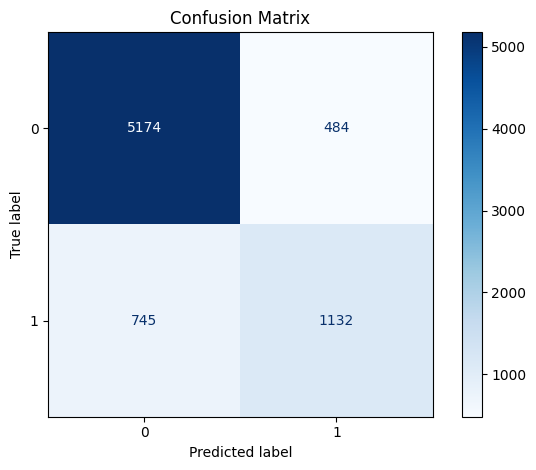

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
plt.figure(figsize=(8, 6))
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Test on New Data

Test the trained model on new, unseen data samples to verify its income prediction capabilities.

In [8]:
print("Example prediction for a sample from the test set:\n")
example = X_test.iloc[[0]]
example_scaled = scaler.transform(example)
example_selected = selector.transform(example_scaled)
example_pca = pca.transform(example_selected)
prediction = model.predict(example_pca)
print(f"Predicted income class: {prediction[0]}")
print("Actual income class:", y_test.iloc[0])

Example prediction for a sample from the test set:

Predicted income class: 0
Actual income class: 0


In [9]:
# Recompute train/test split and scaled features if this cell runs after a kernel restart
if not all(name in globals() for name in ['X_train_scaled', 'X_test_scaled', 'y_train', 'y_test']):
    if 'df' not in globals():
        dataset_path = globals().get(
            'dataset_path',
            r"C:\Users\omarz\Downloads\adult.csv\adult.csv"
        )
        df = pd.read_csv(dataset_path)
        target = 'income'
        df = df.replace('?', np.nan)
        df.dropna(inplace=True)
        df[target] = df[target].map({'<=50K': 0, '>50K': 1})
        df = pd.get_dummies(df, columns=[
            'workclass', 'education', 'marital.status', 'occupation',
            'relationship', 'race', 'sex', 'native.country'
        ], drop_first=True)
        df = df.sample(frac=1, random_state=42).reset_index(drop=True)

    X = df.drop(columns=[target])
    y = df[target]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

Training Logistic Regression...
Training Support Vector Machine...
Training Random Forest...


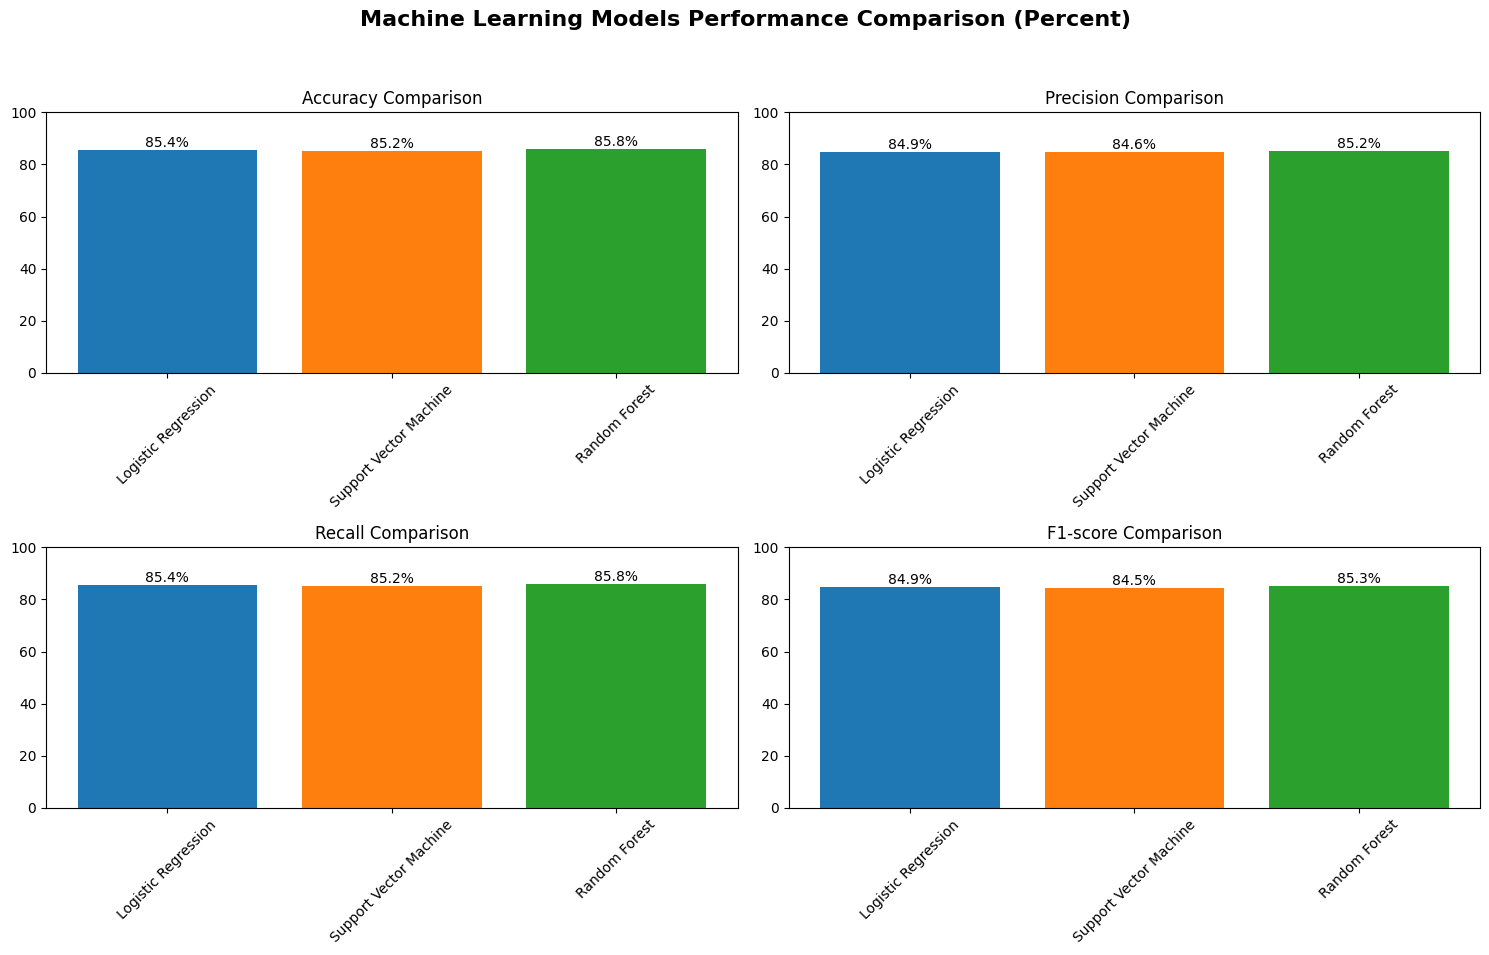


Best Model by Metric:
  Accuracy: Random Forest (85.8%)
  Precision: Random Forest (85.2%)
  Recall: Random Forest (85.8%)
  F1-score: Random Forest (85.3%)


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.svm import SVC


def get_prepared_data(filepath):
    # Load and clean
    df = pd.read_csv(filepath)
    target = 'income'
    df = df.replace('?', np.nan).dropna()
    
    # Encode target and features
    df[target] = df[target].map({'<=50K': 0, '>50K': 1})
    df = pd.get_dummies(df, columns=[
        'workclass', 'education', 'marital.status', 'occupation',
        'relationship', 'race', 'sex', 'native.country'
    ], drop_first=True)
    
    # Split
    X = df.drop(columns=[target])
    y = df[target]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42, stratify=y
    )
    
    # Scale
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    return X_train_scaled, X_test_scaled, y_train, y_test

# --- 1. Data Setup ---
path = r"C:\Users\omarz\Downloads\adult.csv\adult.csv"
X_train, X_test, y_train, y_test = get_prepared_data(path)

# --- 2. Model Definition ---
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Support Vector Machine': SVC(kernel='rbf', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

metrics_funcs = {
    'Accuracy': accuracy_score,
    'Precision': lambda yt, yp: precision_score(yt, yp, average='weighted', zero_division=0),
    'Recall': lambda yt, yp: recall_score(yt, yp, average='weighted', zero_division=0),
    'F1-score': lambda yt, yp: f1_score(yt, yp, average='weighted', zero_division=0),
}

# --- 3. Training & Evaluation ---
results = {}
for name, clf in models.items():
    print(f"Training {name}...")
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    results[name] = {m_name: func(y_test, y_pred) for m_name, func in metrics_funcs.items()}

# --- 4. Visualization ---
results_df = pd.DataFrame(results).T * 100
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Machine Learning Models Performance Comparison (Percent)', fontsize=16, fontweight='bold')
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, metric in enumerate(results_df.columns):
    ax = axes[idx // 2, idx % 2]
    bars = ax.bar(results_df.index, results_df[metric], color=colors)
    ax.set_title(f'{metric} Comparison')
    ax.set_ylim([0, 100])
    ax.tick_params(axis='x', rotation=45)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{bar.get_height():.1f}%', ha='center', va='bottom')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# --- 5. Summary ---
print('\nBest Model by Metric:')
for metric in results_df.columns:
    print(f'  {metric}: {results_df[metric].idxmax()} ({results_df[metric].max():.1f}%)')

Testing different n_estimators:
  n_estimators=10: Accuracy=0.8471
  n_estimators=50: Accuracy=0.8518
  n_estimators=100: Accuracy=0.8524
  n_estimators=200: Accuracy=0.8524
  n_estimators=300: Accuracy=0.8527

Testing different max_depth:
  max_depth=5: Accuracy=0.8279
  max_depth=10: Accuracy=0.8496
  max_depth=15: Accuracy=0.8553
  max_depth=20: Accuracy=0.8580
  max_depth=None: Accuracy=0.8524


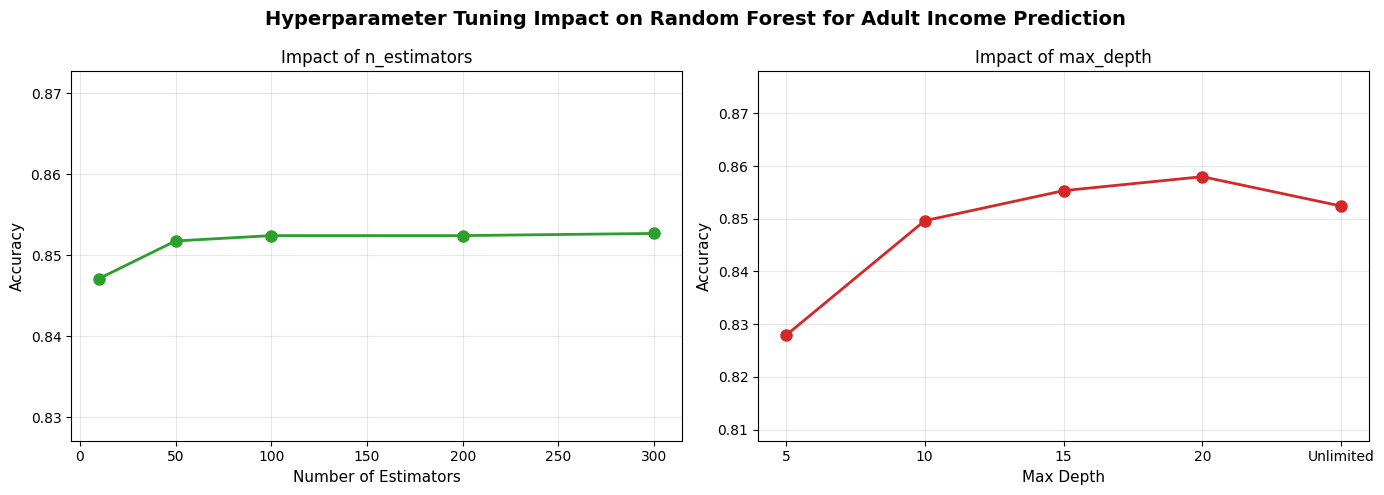

In [13]:
# Rebuild adult income train/test data and scale it before tuning
if 'df' not in globals() or 'X_train_scaled' not in globals() or 'X_test_scaled' not in globals():
    dataset_path = globals().get('dataset_path', r"C:\Users\omarz\Downloads\adult.csv\adult.csv")
    df = pd.read_csv(dataset_path)
    target = 'income'
    df = df.replace('?', np.nan)
    df.dropna(inplace=True)
    df[target] = df[target].map({'<=50K': 0, '>50K': 1})
    df = pd.get_dummies(df, columns=[
        'workclass', 'education', 'marital.status', 'occupation',
        'relationship', 'race', 'sex', 'native.country'
    ], drop_first=True)
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

X = df.drop(columns=[target])
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Test different hyperparameters for the adult income Random Forest
n_estimators_list = [10, 50, 100, 200, 300]
max_depth_list = [5, 10, 15, 20, None]

accuracies_n_estimators = []
accuracies_max_depth = []

print("Testing different n_estimators:")
for n_est in n_estimators_list:
    rf = RandomForestClassifier(n_estimators=n_est, random_state=42)
    rf.fit(X_train_scaled, y_train)
    y_pred_rf = rf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_rf)
    accuracies_n_estimators.append(acc)
    print(f"  n_estimators={n_est}: Accuracy={acc:.4f}")

print("\nTesting different max_depth:")
for depth in max_depth_list:
    rf = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42)
    rf.fit(X_train_scaled, y_train)
    y_pred_rf = rf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred_rf)
    accuracies_max_depth.append(acc)
    depth_label = 'None' if depth is None else str(depth)
    print(f"  max_depth={depth_label}: Accuracy={acc:.4f}")

# Visualize hyperparameter impact
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Hyperparameter Tuning Impact on Random Forest for Adult Income Prediction', fontsize=14, fontweight='bold')

axes[0].plot(n_estimators_list, accuracies_n_estimators, 'o-', linewidth=2, markersize=8, color='#2ca02c')
axes[0].set_xlabel('Number of Estimators', fontsize=11)
axes[0].set_ylabel('Accuracy', fontsize=11)
axes[0].set_title('Impact of n_estimators', fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([min(accuracies_n_estimators) - 0.02, max(accuracies_n_estimators) + 0.02])

depth_labels = [str(d) if d is not None else 'Unlimited' for d in max_depth_list]
axes[1].plot(range(len(max_depth_list)), accuracies_max_depth, 'o-', linewidth=2, markersize=8, color='#d62728')
axes[1].set_xlabel('Max Depth', fontsize=11)
axes[1].set_ylabel('Accuracy', fontsize=11)
axes[1].set_title('Impact of max_depth', fontsize=12)
axes[1].set_xticks(range(len(max_depth_list)))
axes[1].set_xticklabels(depth_labels)
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([min(accuracies_max_depth) - 0.02, max(accuracies_max_depth) + 0.02])

plt.tight_layout()
plt.show()


Selected features: ['capital.gain', 'capital.loss', 'workclass_Self-emp-inc', 'education_Bachelors', 'education_Doctorate', 'education_HS-grad', 'education_Masters', 'education_Prof-school', 'marital.status_Married-civ-spouse', 'marital.status_Never-married', 'occupation_Exec-managerial', 'occupation_Handlers-cleaners', 'occupation_Other-service', 'occupation_Prof-specialty', 'relationship_Not-in-family', 'relationship_Own-child', 'relationship_Unmarried', 'relationship_Wife', 'race_Black', 'sex_Male']
Selected feature shape: (22604, 20)
Training set shape after PCA: (22604, 10)
Testing set shape after PCA: (7535, 10)
Explained variance ratio (top 10 components): 0.8827
Logistic Regression accuracy before feature extraction: 84.68%
Logistic Regression accuracy after feature extraction: 81.90%

Support Vector Machine accuracy before feature extraction: 83.52%
Support Vector Machine accuracy after feature extraction: 81.80%

Random Forest accuracy before feature extraction: 85.28%
Random

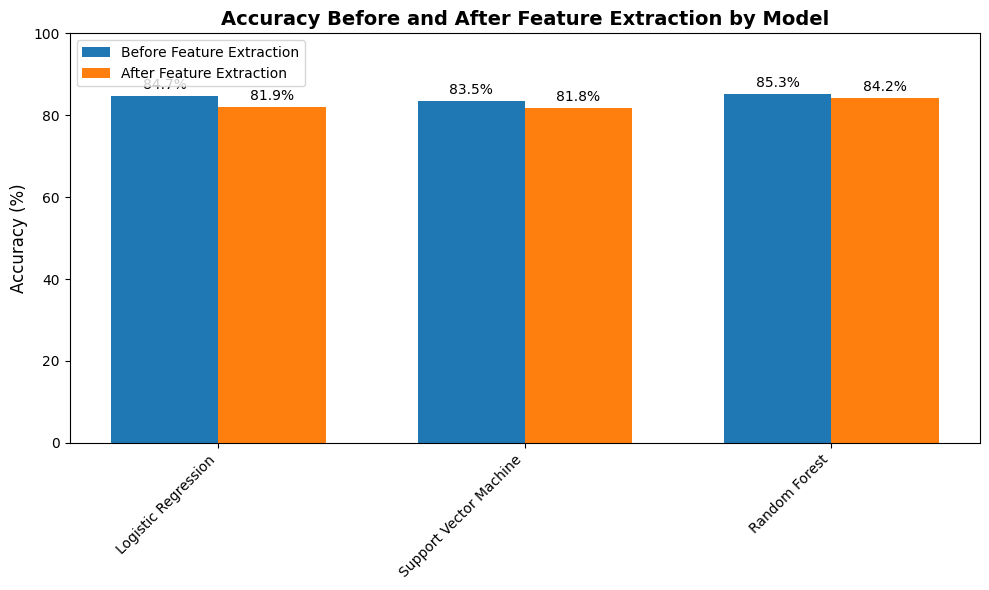

In [16]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import pandas as pd
import numpy as np

# Ensure data is loaded
if 'df' not in globals() or 'target' not in globals():
    dataset_path = globals().get('dataset_path', r"C:\Users\omarz\Downloads\adult.csv\adult.csv")
    df = pd.read_csv(dataset_path)
    target = 'income'
    df = df.replace('?', np.nan)
    df.dropna(inplace=True)
    df[target] = df[target].map({'<=50K': 0, '>50K': 1})
    df = pd.get_dummies(df, columns=[
        'workclass', 'education', 'marital.status', 'occupation',
        'relationship', 'race', 'sex', 'native.country'
    ], drop_first=True)
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Use MinMaxScaler for chi2 (requires non-negative values)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Feature Selection: select the top 20 features using chi-squared
selector = SelectKBest(chi2, k=20)
X_train_selected = selector.fit_transform(X_train_scaled, y_train)
X_test_selected = selector.transform(X_test_scaled)
selected_features = X.columns[selector.get_support()].tolist()
print("Selected features:", selected_features)
print("Selected feature shape:", X_train_selected.shape)

# Feature Extraction: PCA to reduce dimensionality further
pca = PCA(n_components=10, random_state=42)
X_train_pca = pca.fit_transform(X_train_selected)
X_test_pca = pca.transform(X_test_selected)
print("Training set shape after PCA:", X_train_pca.shape)
print("Testing set shape after PCA:", X_test_pca.shape)
print("Explained variance ratio (top 10 components):", np.round(pca.explained_variance_ratio_.sum(), 4))

from sklearn.base import clone

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Support Vector Machine': SVC(kernel='rbf', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
}

accuracy_before = []
accuracy_after = []

for name, clf in models.items():
    clf_before = clone(clf)
    clf_before.fit(X_train_scaled, y_train)
    acc_before = accuracy_score(y_test, clf_before.predict(X_test_scaled)) * 100
    accuracy_before.append(acc_before)

    clf_after = clone(clf)
    clf_after.fit(X_train_pca, y_train)
    acc_after = accuracy_score(y_test, clf_after.predict(X_test_pca)) * 100
    accuracy_after.append(acc_after)

    print(f"{name} accuracy before feature extraction: {acc_before:.2f}%")
    print(f"{name} accuracy after feature extraction: {acc_after:.2f}%\n")

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(x - width/2, accuracy_before, width, label='Before Feature Extraction', color='#1f77b4')
ax.bar(x + width/2, accuracy_after, width, label='After Feature Extraction', color='#ff7f0e')

ax.set_title('Accuracy Before and After Feature Extraction by Model', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_ylim([0, 100])
ax.set_xticks(x)
ax.set_xticklabels(list(models.keys()), rotation=45, ha='right')
ax.legend()

for i in range(len(models)):
    ax.text(x[i] - width/2, accuracy_before[i] + 1, f'{accuracy_before[i]:.1f}%', ha='center', va='bottom', fontsize=10)
    ax.text(x[i] + width/2, accuracy_after[i] + 1, f'{accuracy_after[i]:.1f}%', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()


## 7. Evaluate Model Performance

Evaluate the trained Random Forest model on the Adult Income test set and inspect accuracy for the `income` target.

## 8. Summary and Next Steps

Summarize results from the Adult Income prediction experiment and outline next steps for model tuning and deployment.